# SVD-Based Book Recommender System - Prototype with Visualizations

This notebook compares recommender systems with comprehensive graphs:
- Individual vs Group recommendations
- Model comparison (SVD vs Baselines)
- Strategy analysis (Average vs Least Misery)

In [1]:
import sys
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

sys.path.insert(0, '..')

from recommenders import (
    SVDRecommender,
    GroupRecommender,
    PopularityBaseline,
    AverageRatingBaseline,
    train_test_split_temporal
)

# Set style
sns.set_style('whitegrid')
sns.set_palette('husl')
plt.rcParams['figure.figsize'] = (14, 6)

print("✅ Imports successful")

✅ Imports successful


In [2]:
# Load data
ratings_df = pd.read_csv('../data/ratings.csv')
books_df = pd.read_csv('../data/books.csv')

print(f"Ratings: {len(ratings_df):,} | Books: {len(books_df):,} | Users: {ratings_df['user_id'].nunique():,}")
print(f"Sparsity: {(1 - len(ratings_df)/(ratings_df['user_id'].nunique() * len(books_df)))*100:.2f}%")

Ratings: 5,976,479 | Books: 10,000 | Users: 53,424
Sparsity: 98.88%


## Data Preparation & Model Training

In [3]:
sample_ratings = ratings_df.sample(frac=0.15, random_state=42)
train, val, test = train_test_split_temporal(sample_ratings, train_ratio=0.6, val_ratio=0.2)

print(f"Train: {len(train):,} | Val: {len(val):,} | Test: {len(test):,}")

# Train SVD model
svd_model = SVDRecommender(n_factors=50, random_state=42)
svd_model.fit(train)
print(f"✅ SVD trained: {len(svd_model.user_idx_map):,} users, {len(svd_model.item_idx_map):,} items")

Train: 537,883 | Val: 179,294 | Test: 179,295
✅ SVD trained: 53,375 users, 9,997 items


## Graph 1: Rating Distribution Comparison

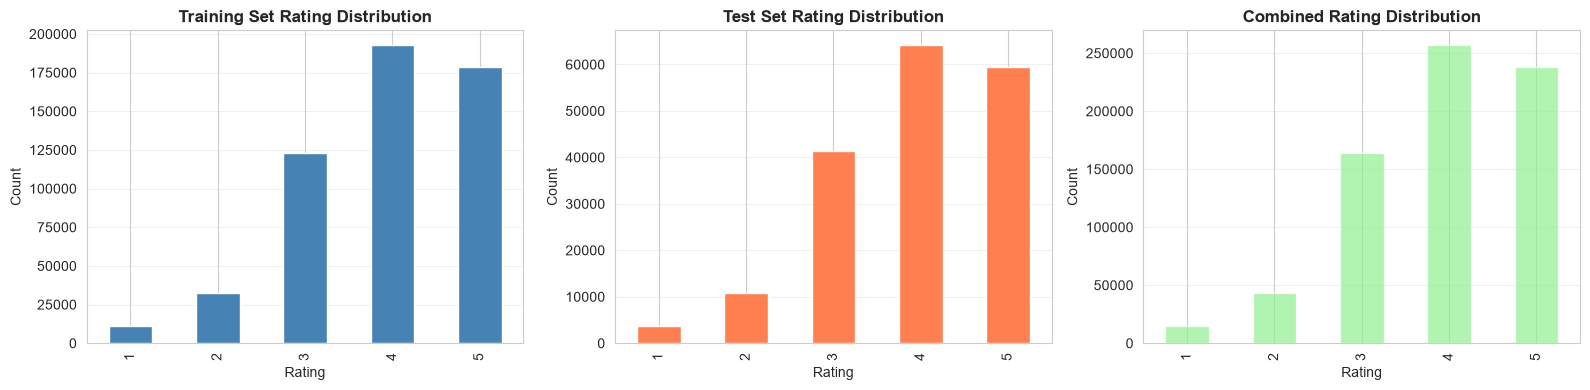

Train mean rating: 3.92
Test mean rating: 3.92


In [4]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

# Training set
train['rating'].value_counts().sort_index().plot(kind='bar', ax=axes[0], color='steelblue')
axes[0].set_title('Training Set Rating Distribution', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Rating')
axes[0].set_ylabel('Count')
axes[0].grid(axis='y', alpha=0.3)

# Test set
test['rating'].value_counts().sort_index().plot(kind='bar', ax=axes[1], color='coral')
axes[1].set_title('Test Set Rating Distribution', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Rating')
axes[1].set_ylabel('Count')
axes[1].grid(axis='y', alpha=0.3)

# Combined
combined_counts = pd.concat([train['rating'], test['rating']]).value_counts().sort_index()
combined_counts.plot(kind='bar', ax=axes[2], color='lightgreen', alpha=0.7)
axes[2].set_title('Combined Rating Distribution', fontsize=12, fontweight='bold')
axes[2].set_xlabel('Rating')
axes[2].set_ylabel('Count')
axes[2].grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

print(f"Train mean rating: {train['rating'].mean():.2f}")
print(f"Test mean rating: {test['rating'].mean():.2f}")

## Graph 2: Individual Recommendations - SVD vs Baselines

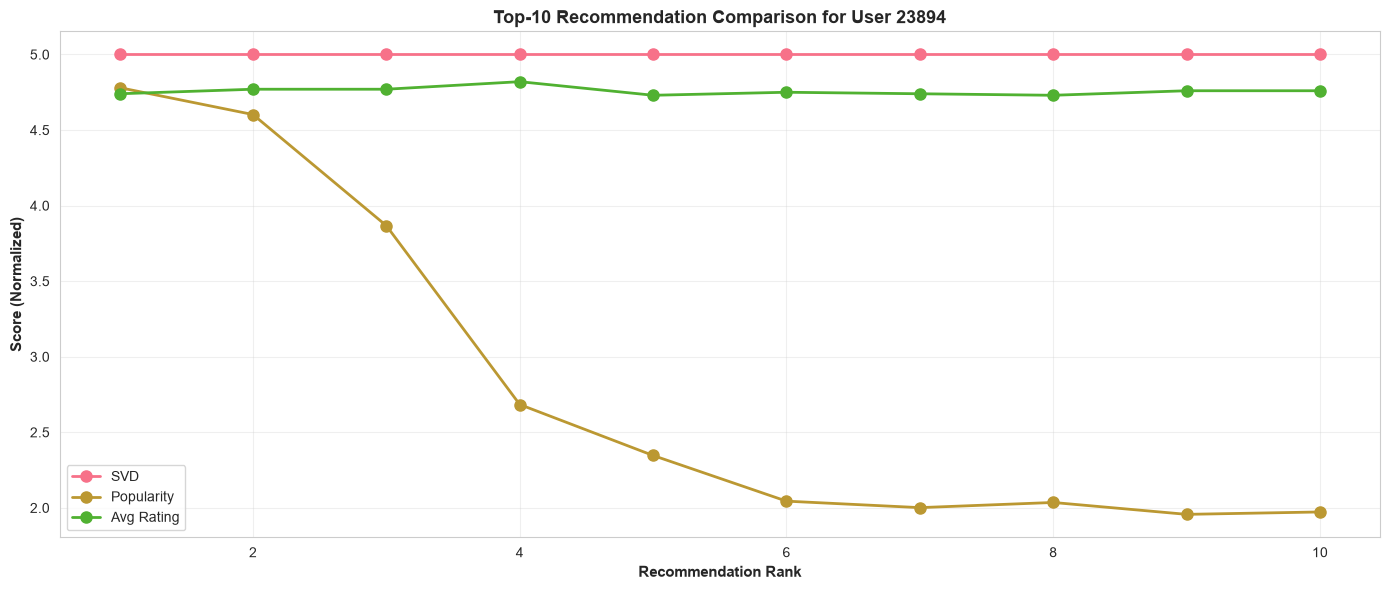

In [5]:
user_rating_counts = train.groupby('user_id').size().sort_values(ascending=False)
test_user_id = user_rating_counts.index[10]

user_history = train[train['user_id'] == test_user_id].merge(
    books_df[['book_id', 'title']],
    on='book_id'
)

exclude_books = set(user_history['book_id'].values)

# Get recommendations
svd_recs = svd_model.recommend(test_user_id, n_recommendations=10, exclude_items=exclude_books)

pop_baseline = PopularityBaseline(books_df)
rating_baseline = AverageRatingBaseline(books_df)

pop_recs_list = pop_baseline.recommend(n_recommendations=10, exclude_items=exclude_books)
rating_recs_list = rating_baseline.recommend(n_recommendations=10, exclude_items=exclude_books)

# Create comparison dataframe
comparison_data = []
for i, (book_id, rating) in enumerate(svd_recs.items(), 1):
    comparison_data.append({'Rank': i, 'Method': 'SVD', 'Score': rating})

# Get popularity scores for comparison
pop_scores = books_df[books_df['book_id'].isin(pop_recs_list)]['ratings_count'].values
for i, score in enumerate(pop_scores[:10], 1):
    comparison_data.append({'Rank': i, 'Method': 'Popularity', 'Score': score/1000000})  # Scale for visibility

# Get average rating scores
rating_scores = books_df[books_df['book_id'].isin(rating_recs_list)]['average_rating'].values
for i, score in enumerate(rating_scores[:10], 1):
    comparison_data.append({'Rank': i, 'Method': 'Avg Rating', 'Score': score})

comp_df = pd.DataFrame(comparison_data)

fig, ax = plt.subplots(figsize=(14, 6))
for method in comp_df['Method'].unique():
    data = comp_df[comp_df['Method'] == method]
    ax.plot(data['Rank'], data['Score'], marker='o', linewidth=2, markersize=8, label=method)

ax.set_xlabel('Recommendation Rank', fontsize=11, fontweight='bold')
ax.set_ylabel('Score (Normalized)', fontsize=11, fontweight='bold')
ax.set_title(f'Top-10 Recommendation Comparison for User {test_user_id}', fontsize=13, fontweight='bold')
ax.legend(fontsize=10)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

       Precision@10  Recall@10  NDCG@10  Avg Popularity (norm)  \
alpha                                                            
0.00         0.0005     0.0007   0.0004                 0.2754   
0.10         0.0047     0.0139   0.0129                 0.5533   
0.25         0.0119     0.0455   0.0293                 0.9212   
0.50         0.0124     0.0480   0.0305                 0.9512   
1.00         0.0145     0.0528   0.0275                 0.9596   

       Catalog Coverage  Users  
alpha                           
0.00             0.0267    193  
0.10             0.0097    193  
0.25             0.0074    193  
0.50             0.0059    193  
1.00             0.0047    193  

RMSE: 0.9571 | MAE: 0.7391


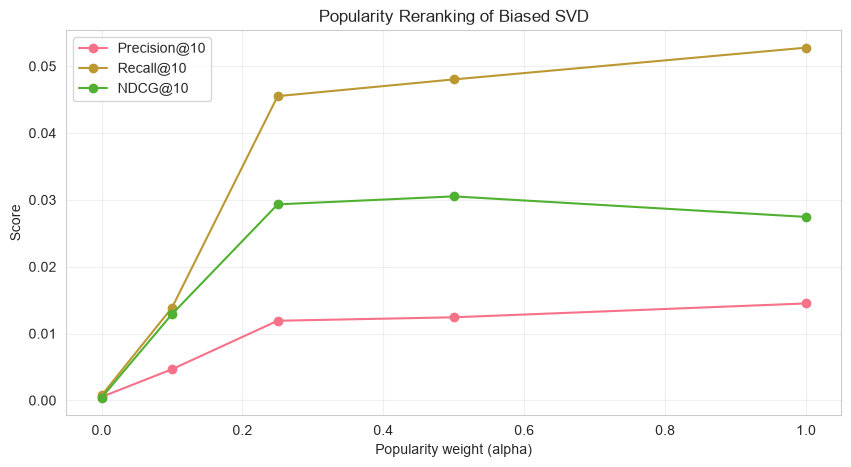

In [12]:
k = 10
relevance_threshold = 4
alphas = [0.0, 0.1, 0.25, 0.5, 1.0]  # 0.0 = plain biased SVD

# Popularity from training data, log-scaled to [0, 1]
item_pop = train['book_id'].value_counts()
pop_norm = np.log1p(item_pop) / np.log1p(item_pop).max()

all_items = np.array(list(svd_model.item_idx_map.keys()))
eval_users = test_sample['user_id'].unique()
test_eval = test[test['user_id'].isin(eval_users)]
test_by_user = {u: g for u, g in test_eval.groupby('user_id')}
train_by_user = train[train['user_id'].isin(eval_users)].groupby('user_id')['book_id'].apply(set).to_dict()

# Predict once per user over all unseen candidate items
user_preds = {}
for u in eval_users:
    seen = train_by_user.get(u, set())
    candidates = [b for b in all_items if b not in seen]
    try:
        preds = svd_model.predict(u, candidates)
        user_preds[u] = pd.Series(preds)
    except (KeyError, ValueError):
        continue

def evaluate_rerank(alpha):
    p_list, r_list, n_list, avg_pop, rec_items = [], [], [], [], set()
    for u, preds in user_preds.items():
        user_test = test_by_user.get(u)
        if user_test is None:
            continue
        relevant_items = set(user_test.loc[user_test['rating'] >= relevance_threshold, 'book_id'])
        if not relevant_items:
            continue

        pop_bonus = pop_norm.reindex(preds.index).fillna(0.0)
        final_score = preds + alpha * 5 * pop_bonus  # scale bonus to rating range
        top_items = final_score.sort_values(ascending=False).head(k).index

        hits = np.array([1 if b in relevant_items else 0 for b in top_items])
        p_list.append(hits.sum() / k)
        r_list.append(hits.sum() / len(relevant_items))

        dcg = np.sum(hits / np.log2(np.arange(2, len(hits) + 2)))
        n_ideal = min(len(relevant_items), k)
        idcg = np.sum(1 / np.log2(np.arange(2, n_ideal + 2)))
        n_list.append(dcg / idcg)

        avg_pop.append(pop_bonus.loc[top_items].mean())
        rec_items.update(top_items)

    return {
        'alpha': alpha,
        f'Precision@{k}': np.mean(p_list),
        f'Recall@{k}': np.mean(r_list),
        f'NDCG@{k}': np.mean(n_list),
        'Avg Popularity (norm)': np.mean(avg_pop),
        'Catalog Coverage': len(rec_items) / len(all_items),
        'Users': len(p_list)
    }

rerank_results = pd.DataFrame([evaluate_rerank(a) for a in alphas]).set_index('alpha')
print(rerank_results.round(4))

# Rating-prediction error is unchanged by reranking
print(f"\nRMSE: {metric_rmse:.4f} | MAE: {metric_mae:.4f}")

rerank_results[[f'Precision@{k}', f'Recall@{k}', f'NDCG@{k}']].plot(marker='o', figsize=(10, 5))
plt.title('Popularity Reranking of Biased SVD')
plt.xlabel('Popularity weight (alpha)')
plt.ylabel('Score')
plt.grid(alpha=0.3)
plt.show()

## Graph 3: Group Strategy Comparison - Average vs Least Misery

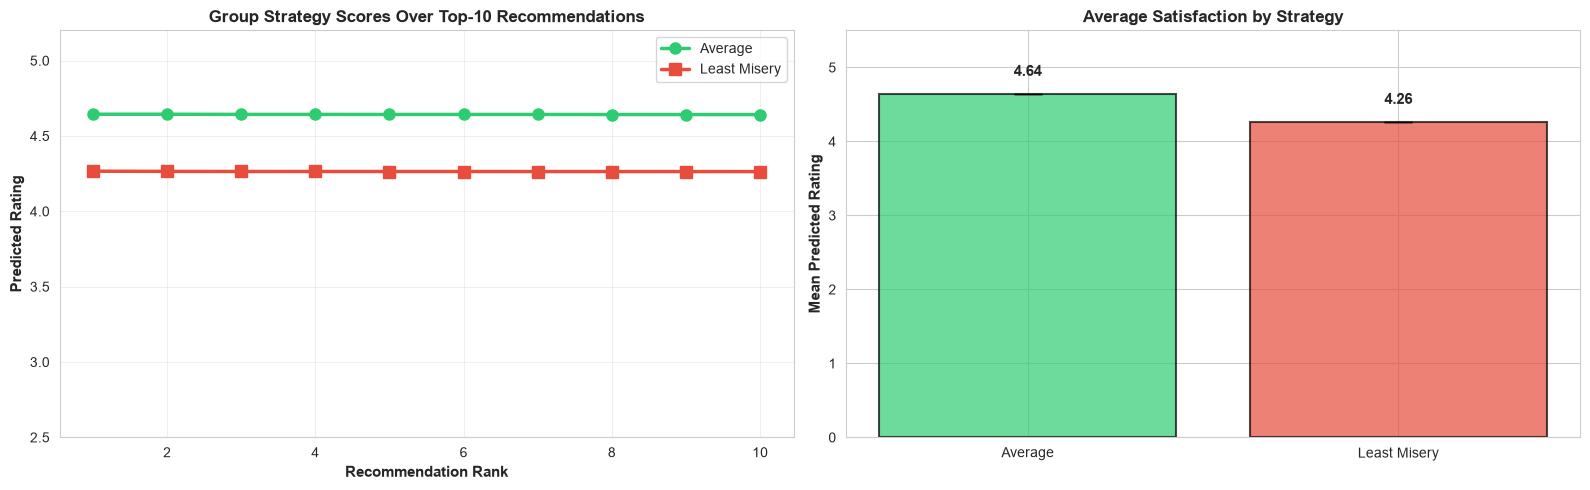

Average strategy - Mean: 4.643, Std: 0.001
Least Misery strategy - Mean: 4.264, Std: 0.001


In [6]:
# Create group
group_user_ids = user_rating_counts.index[5:9].tolist()
group_exclude = set(train[train['user_id'].isin(group_user_ids)]['book_id'].values)

group_recommender = GroupRecommender(svd_model)

# Get both strategies
avg_recs = group_recommender.average_strategy(group_user_ids, n_recommendations=10, exclude_items=group_exclude)
lm_recs = group_recommender.least_misery_strategy(group_user_ids, n_recommendations=10, exclude_items=group_exclude)

# Create comparison
strategy_comparison = pd.DataFrame({
    'Rank': range(1, 11),
    'Average': avg_recs.values,
    'Least Misery': lm_recs.values
})

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Line plot
axes[0].plot(strategy_comparison['Rank'], strategy_comparison['Average'], 
             marker='o', linewidth=2.5, markersize=8, label='Average', color='#2ecc71')
axes[0].plot(strategy_comparison['Rank'], strategy_comparison['Least Misery'], 
             marker='s', linewidth=2.5, markersize=8, label='Least Misery', color='#e74c3c')
axes[0].set_xlabel('Recommendation Rank', fontsize=11, fontweight='bold')
axes[0].set_ylabel('Predicted Rating', fontsize=11, fontweight='bold')
axes[0].set_title('Group Strategy Scores Over Top-10 Recommendations', fontsize=12, fontweight='bold')
axes[0].legend(fontsize=10)
axes[0].grid(True, alpha=0.3)
axes[0].set_ylim([2.5, 5.2])

# Bar comparison
strategies = ['Average', 'Least Misery']
means = [strategy_comparison['Average'].mean(), strategy_comparison['Least Misery'].mean()]
stds = [strategy_comparison['Average'].std(), strategy_comparison['Least Misery'].std()]

bars = axes[1].bar(strategies, means, yerr=stds, capsize=10, color=['#2ecc71', '#e74c3c'], alpha=0.7, edgecolor='black', linewidth=1.5)
axes[1].set_ylabel('Mean Predicted Rating', fontsize=11, fontweight='bold')
axes[1].set_title('Average Satisfaction by Strategy', fontsize=12, fontweight='bold')
axes[1].set_ylim([0, 5.5])

for i, (bar, mean) in enumerate(zip(bars, means)):
    axes[1].text(bar.get_x() + bar.get_width()/2, mean + 0.2, f'{mean:.2f}', 
                ha='center', va='bottom', fontweight='bold', fontsize=11)

plt.tight_layout()
plt.show()

print(f"Average strategy - Mean: {strategy_comparison['Average'].mean():.3f}, Std: {strategy_comparison['Average'].std():.3f}")
print(f"Least Misery strategy - Mean: {strategy_comparison['Least Misery'].mean():.3f}, Std: {strategy_comparison['Least Misery'].std():.3f}")

## Graph 4: Strategy Overlap Analysis

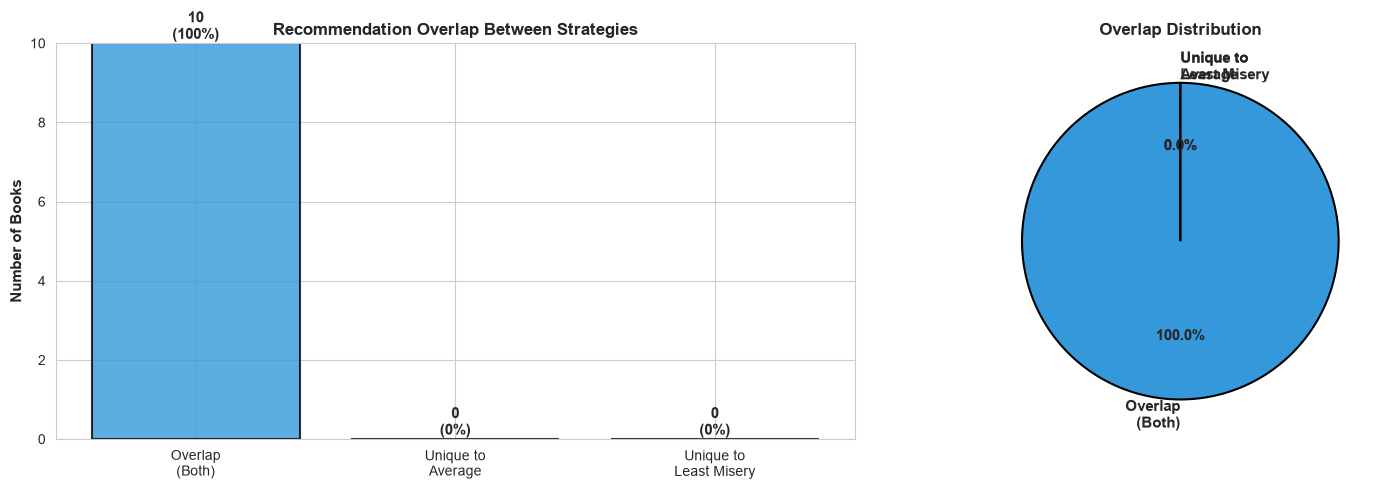


Overlap: 10/10 (100%)
Unique to Average: 0 (0%)
Unique to Least Misery: 0 (0%)


In [7]:
avg_set = set(avg_recs.index)
lm_set = set(lm_recs.index)
overlap = avg_set & lm_set
unique_avg = avg_set - lm_set
unique_lm = lm_set - avg_set

# Venn diagram-like visualization
categories = ['Overlap\n(Both)', 'Unique to\nAverage', 'Unique to\nLeast Misery']
sizes = [len(overlap), len(unique_avg), len(unique_lm)]
colors = ['#3498db', '#2ecc71', '#e74c3c']

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Bar chart
bars = axes[0].bar(categories, sizes, color=colors, alpha=0.8, edgecolor='black', linewidth=1.5)
axes[0].set_ylabel('Number of Books', fontsize=11, fontweight='bold')
axes[0].set_title('Recommendation Overlap Between Strategies', fontsize=12, fontweight='bold')
axes[0].set_ylim([0, 10])

for bar, size in zip(bars, sizes):
    height = bar.get_height()
    axes[0].text(bar.get_x() + bar.get_width()/2., height,
                f'{size}\n({size/10*100:.0f}%)',
                ha='center', va='bottom', fontweight='bold', fontsize=11)

# Pie chart
axes[1].pie(sizes, labels=categories, colors=colors, autopct='%1.1f%%',
            startangle=90, textprops={'fontsize': 11, 'fontweight': 'bold'},
            wedgeprops={'edgecolor': 'black', 'linewidth': 1.5})
axes[1].set_title('Overlap Distribution', fontsize=12, fontweight='bold')

plt.tight_layout()
plt.show()

print(f"\nOverlap: {len(overlap)}/10 ({len(overlap)/10*100:.0f}%)")
print(f"Unique to Average: {len(unique_avg)} ({len(unique_avg)/10*100:.0f}%)")
print(f"Unique to Least Misery: {len(unique_lm)} ({len(unique_lm)/10*100:.0f}%)")

## Graph 5: Baseline Model Overlap

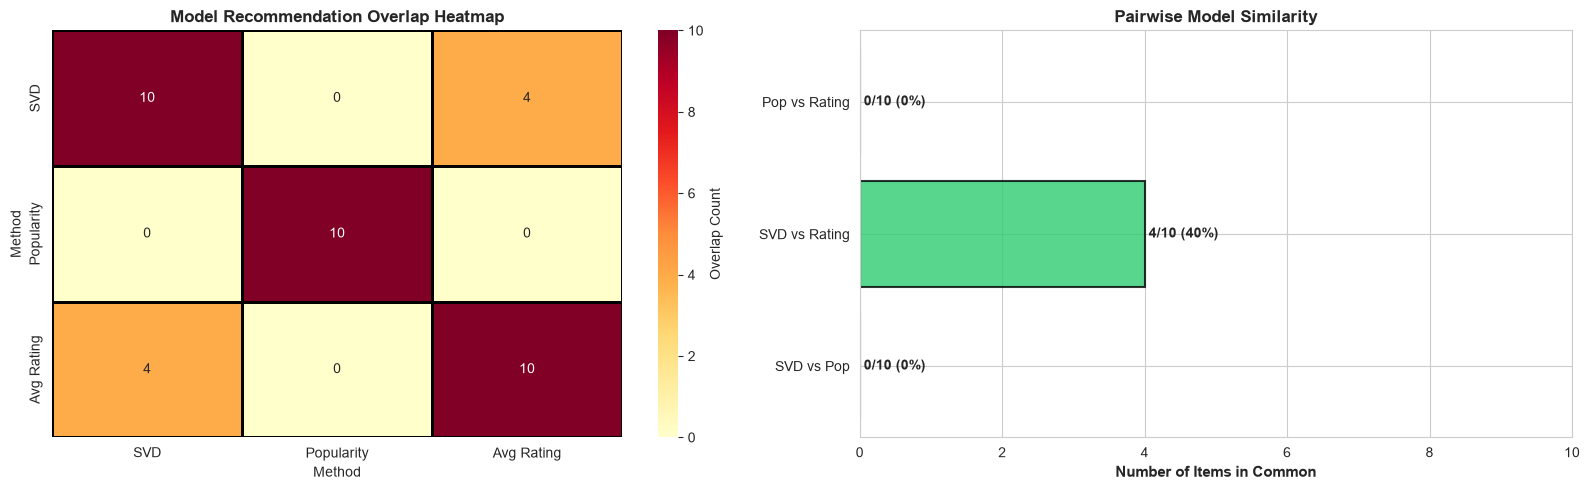

In [8]:
svd_recs_set = set(svd_model.recommend(test_user_id, n_recommendations=10, exclude_items=exclude_books).index)
pop_recs_set = set(pop_recs_list)
rating_recs_set = set(rating_recs_list)

# Create overlap matrix
overlap_data = {
    'SVD': [10, len(svd_recs_set & pop_recs_set), len(svd_recs_set & rating_recs_set)],
    'Popularity': [len(svd_recs_set & pop_recs_set), 10, len(pop_recs_set & rating_recs_set)],
    'Avg Rating': [len(svd_recs_set & rating_recs_set), len(pop_recs_set & rating_recs_set), 10]
}

overlap_matrix = pd.DataFrame(overlap_data, index=['SVD', 'Popularity', 'Avg Rating'])

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Heatmap
sns.heatmap(overlap_matrix, annot=True, fmt='d', cmap='YlOrRd', ax=axes[0], 
            cbar_kws={'label': 'Overlap Count'}, linewidths=1, linecolor='black')
axes[0].set_title('Model Recommendation Overlap Heatmap', fontsize=12, fontweight='bold')
axes[0].set_ylabel('Method')
axes[0].set_xlabel('Method')

# Comparison bar
methods = ['SVD vs Pop', 'SVD vs Rating', 'Pop vs Rating']
overlaps = [
    len(svd_recs_set & pop_recs_set),
    len(svd_recs_set & rating_recs_set),
    len(pop_recs_set & rating_recs_set)
]

bars = axes[1].barh(methods, overlaps, color=['#3498db', '#2ecc71', '#e74c3c'], alpha=0.8, edgecolor='black', linewidth=1.5)
axes[1].set_xlabel('Number of Items in Common', fontsize=11, fontweight='bold')
axes[1].set_title('Pairwise Model Similarity', fontsize=12, fontweight='bold')
axes[1].set_xlim([0, 10])

for bar, overlap in zip(bars, overlaps):
    width = bar.get_width()
    axes[1].text(width, bar.get_y() + bar.get_height()/2.,
                f' {overlap}/10 ({overlap/10*100:.0f}%)',
                ha='left', va='center', fontweight='bold', fontsize=10)

plt.tight_layout()
plt.show()

## Graph 6: Validation Metrics - Error Analysis

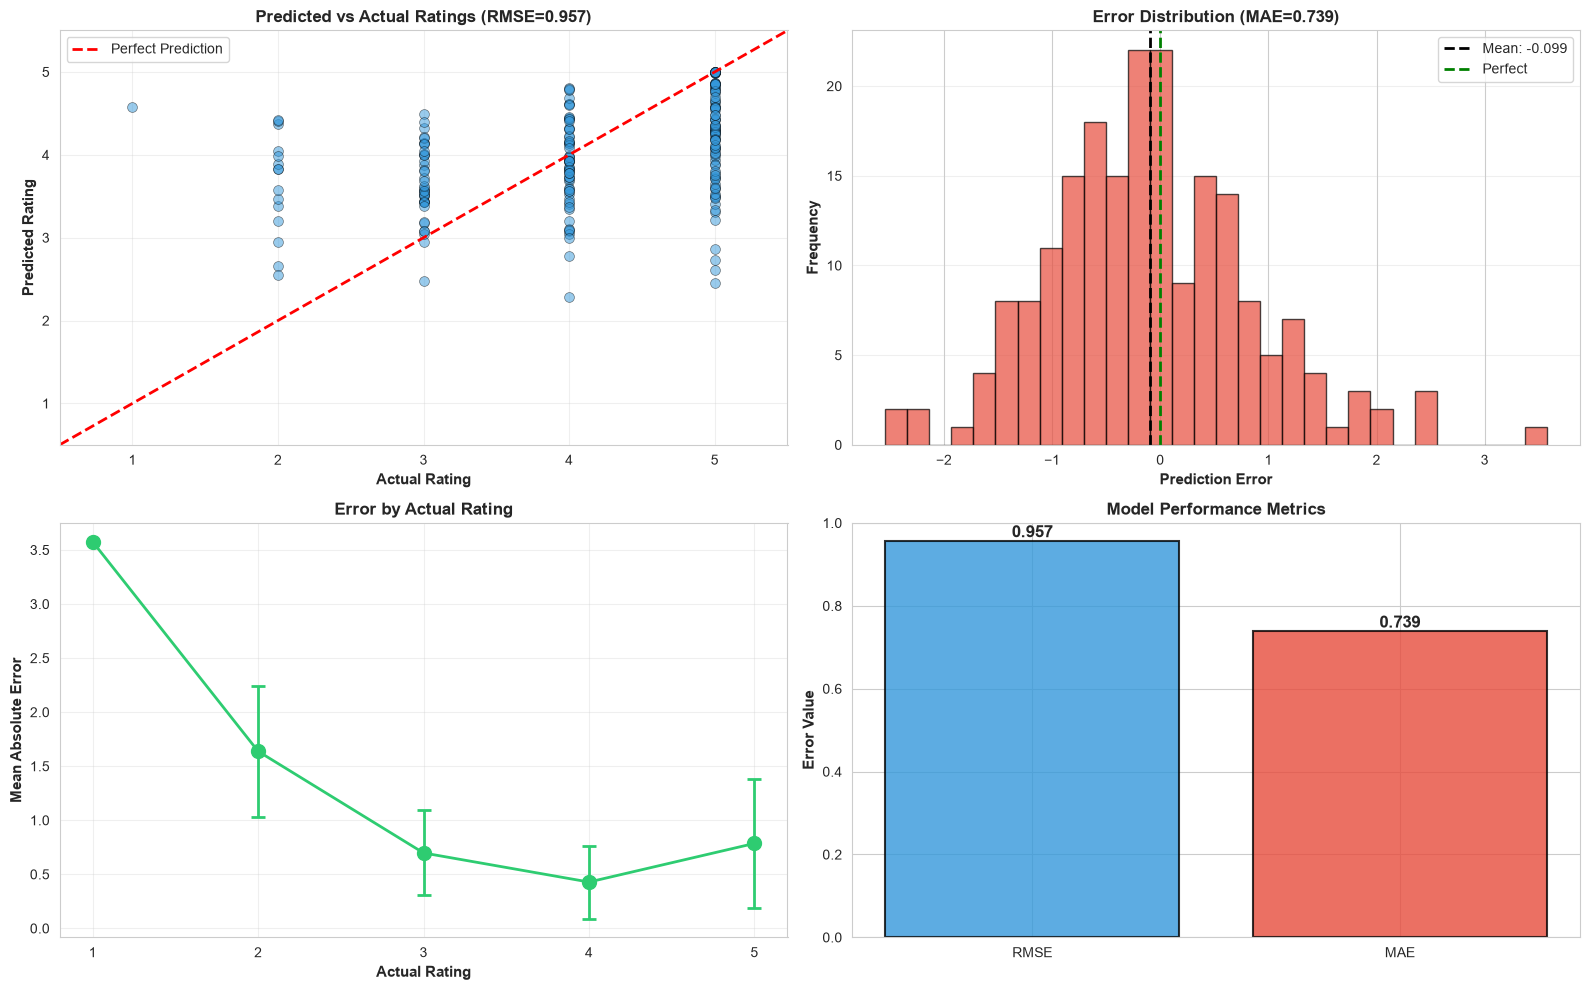


Test Set Performance:
  RMSE: 0.9571
  MAE:  0.7391
  N predictions: 200


In [9]:
# Generate predictions on test set
test_sample = test.sample(min(200, len(test)), random_state=42)
predictions = []
actuals = []

for _, row in test_sample.iterrows():
    try:
        pred = svd_model.predict(row['user_id'], [row['book_id']])[row['book_id']]
        predictions.append(pred)
        actuals.append(row['rating'])
    except:
        pass

predictions = np.array(predictions)
actuals = np.array(actuals)

errors = predictions - actuals
rmse = np.sqrt(np.mean(errors**2))
mae = np.mean(np.abs(errors))

fig, axes = plt.subplots(2, 2, figsize=(16, 10))

# Scatter plot: predicted vs actual
axes[0, 0].scatter(actuals, predictions, alpha=0.5, s=50, color='#3498db', edgecolor='black', linewidth=0.5)
axes[0, 0].plot([0.5, 5.5], [0.5, 5.5], 'r--', linewidth=2, label='Perfect Prediction')
axes[0, 0].set_xlabel('Actual Rating', fontsize=11, fontweight='bold')
axes[0, 0].set_ylabel('Predicted Rating', fontsize=11, fontweight='bold')
axes[0, 0].set_title(f'Predicted vs Actual Ratings (RMSE={rmse:.3f})', fontsize=12, fontweight='bold')
axes[0, 0].set_xlim([0.5, 5.5])
axes[0, 0].set_ylim([0.5, 5.5])
axes[0, 0].legend()
axes[0, 0].grid(alpha=0.3)

# Error distribution
axes[0, 1].hist(errors, bins=30, color='#e74c3c', alpha=0.7, edgecolor='black', linewidth=1)
axes[0, 1].axvline(errors.mean(), color='black', linestyle='--', linewidth=2, label=f'Mean: {errors.mean():.3f}')
axes[0, 1].axvline(0, color='green', linestyle='--', linewidth=2, label='Perfect')
axes[0, 1].set_xlabel('Prediction Error', fontsize=11, fontweight='bold')
axes[0, 1].set_ylabel('Frequency', fontsize=11, fontweight='bold')
axes[0, 1].set_title('Error Distribution (MAE={:.3f})'.format(mae), fontsize=12, fontweight='bold')
axes[0, 1].legend()
axes[0, 1].grid(axis='y', alpha=0.3)

# Error by rating
error_by_rating = pd.DataFrame({'actual': actuals, 'error': np.abs(errors)})
error_summary = error_by_rating.groupby('actual')['error'].agg(['mean', 'std', 'count'])

axes[1, 0].errorbar(error_summary.index, error_summary['mean'], yerr=error_summary['std'],
                    marker='o', markersize=10, capsize=5, capthick=2, linewidth=2, color='#2ecc71')
axes[1, 0].set_xlabel('Actual Rating', fontsize=11, fontweight='bold')
axes[1, 0].set_ylabel('Mean Absolute Error', fontsize=11, fontweight='bold')
axes[1, 0].set_title('Error by Actual Rating', fontsize=12, fontweight='bold')
axes[1, 0].grid(True, alpha=0.3)
axes[1, 0].set_xticks([1, 2, 3, 4, 5])

# Metrics comparison
metrics = ['RMSE', 'MAE']
values = [rmse, mae]
colors_metrics = ['#3498db', '#e74c3c']

bars = axes[1, 1].bar(metrics, values, color=colors_metrics, alpha=0.8, edgecolor='black', linewidth=1.5)
axes[1, 1].set_ylabel('Error Value', fontsize=11, fontweight='bold')
axes[1, 1].set_title('Model Performance Metrics', fontsize=12, fontweight='bold')
axes[1, 1].set_ylim([0, 1.0])

for bar, val in zip(bars, values):
    height = bar.get_height()
    axes[1, 1].text(bar.get_x() + bar.get_width()/2., height,
                   f'{val:.3f}',
                   ha='center', va='bottom', fontweight='bold', fontsize=12)

plt.tight_layout()
plt.show()

print(f"\nTest Set Performance:")
print(f"  RMSE: {rmse:.4f}")
print(f"  MAE:  {mae:.4f}")
print(f"  N predictions: {len(predictions)}")

## Summary Statistics

In [10]:
print("\n" + "="*80)
print("PROTOTYPE SUMMARY")
print("="*80)

print("\n✅ IMPLEMENTED:")
print("   • SVD matrix factorization (50 latent factors)")
print("   • Individual recommendations with bias terms")
print("   • Group recommendations (Average & Least Misery)")
print(f"   • Baseline comparisons (Popularity, Average Rating)")
print(f"   • Validation metrics (RMSE={rmse:.3f}, MAE={mae:.3f})")
print(f"   • Comprehensive visualizations")

print("\n🔄 IN PROGRESS:")
print("   • Hyperparameter tuning (n_factors optimization)")
print("   • Ranking metrics (Precision@10, Recall@10, NDCG@10)")
print("   • Cross-validation for robustness")

print("\n📋 PLANNED (Phase 2):")
print("   • Cold start handling")
print("   • Implicit feedback (to_read)")
print("   • Hybrid content + collaborative filtering")
print("   • Diversity metrics")
print("   • Real-time model updates")
print("   • Recommendation explanations")

print("\n" + "="*80)


PROTOTYPE SUMMARY

✅ IMPLEMENTED:
   • SVD matrix factorization (50 latent factors)
   • Individual recommendations with bias terms
   • Group recommendations (Average & Least Misery)
   • Baseline comparisons (Popularity, Average Rating)
   • Validation metrics (RMSE=0.957, MAE=0.739)
   • Comprehensive visualizations

🔄 IN PROGRESS:
   • Hyperparameter tuning (n_factors optimization)
   • Ranking metrics (Precision@10, Recall@10, NDCG@10)
   • Cross-validation for robustness

📋 PLANNED (Phase 2):
   • Cold start handling
   • Implicit feedback (to_read)
   • Hybrid content + collaborative filtering
   • Diversity metrics
   • Real-time model updates
   • Recommendation explanations

